# How DJINN builds a network from a tree

This notebook goes through what `fit()` does inside: grow a decision tree, turn
it into the architecture and starting weights of a neural network, then train
that network. It uses the functions in `djinn.random_forest` directly. See the
[theory page](../theory.rst) for the full description.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import plot_tree

from djinn import DJINN_Regressor
from djinn.random_forest import fit_scalers, train_forest, tree_to_nn_weights

In [2]:
X, y = fetch_california_housing(return_X_y=True)
rng = np.random.default_rng(0)
idx = rng.choice(len(y), 3000, replace=False)
X_train, X_test, y_train, y_test = train_test_split(
    X[idx], y[idx], test_size=0.2, random_state=0
)
X_train.shape, X_test.shape

((2400, 8), (600, 8))

## 1. Grow a tree

DJINN scales the data to [0, 1] and fits a random forest with one tree per
network. A shallow tree keeps the network small enough to look at.

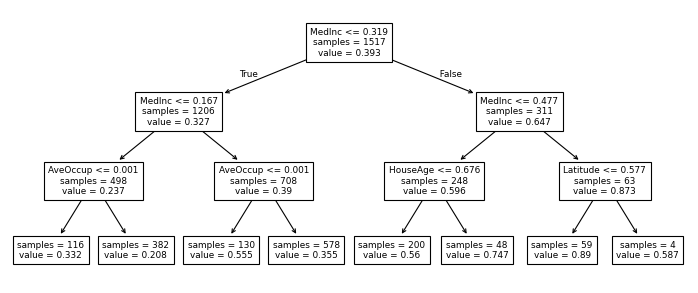

In [3]:
depth = 3
feature_names = fetch_california_housing().feature_names
Y_train = y_train.reshape(-1, 1)

xscale, yscale = fit_scalers(X_train, Y_train, regression=True)
forest = train_forest(
    X_train, Y_train, 1, depth, xscale, yscale, regression=True, seed=0
)
tree = forest.estimators_[0]

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=80)
plot_tree(tree, feature_names=feature_names, ax=ax, fontsize=8, impurity=False)
plt.show()

## 2. Map the tree to a network

Each depth of the tree becomes a layer of the network:

- The input layer has one neuron per feature.
- Every hidden layer keeps all the neurons of the layer before it, and adds one
  new neuron for each split at that depth of the tree.
- The output layer has one neuron per target.

So a tree of depth 3 gives a network with 2 hidden layers.

In [4]:
ttn = tree_to_nn_weights(True, X_train, Y_train, 1, forest, seed=0)
arch = ttn["network_shape"]["tree_0"]
weights = [ttn["weights"]["tree_0"][i] for i in range(len(arch) - 1)]
print("Neurons per layer:", arch)

Neurons per layer: [ 8 10 14  1]


Only the connections that follow the tree get a starting weight:

- The neuron for a split is connected to the neuron for its parent split (or,
  for the root's children, to the root's input feature) and to the input
  feature the split itself uses. These get small random values.
- An input feature is passed on to the next layer with a weight of 1 as long
  as a deeper split still uses it.
- Where a branch ends in a leaf, the parent's neuron is passed straight through
  to the output with weights of 1.

Everything else starts at zero, which is why the matrices are mostly blank.

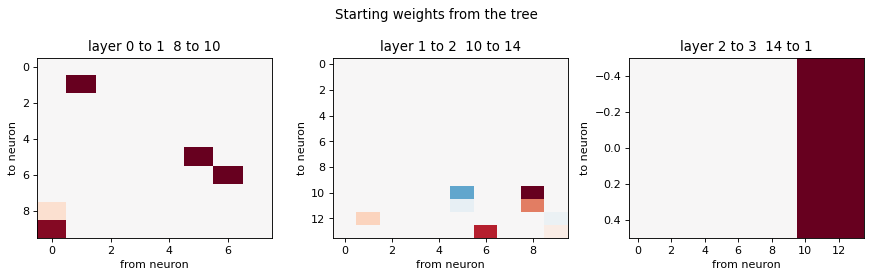

layer 0 to 1: 5 of 80 weights set
layer 1 to 2: 8 of 140 weights set
layer 2 to 3: 4 of 14 weights set


In [5]:
def show_weights(mats, title):
    fig, axs = plt.subplots(1, len(mats), figsize=(11, 3.5), dpi=80)
    for i, (ax, w) in enumerate(zip(axs, mats)):
        lim = np.abs(w).max()
        ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
        ax.set_title(f"layer {i} to {i + 1}  {w.shape[1]} to {w.shape[0]}")
        ax.set_xlabel("from neuron")
        ax.set_ylabel("to neuron")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show_weights(weights, "Starting weights from the tree")
for i, w in enumerate(weights):
    print(f"layer {i} to {i + 1}: {np.count_nonzero(w)} of {w.size} weights set")

## 3. Train

`fit()` repeats the steps above with the same seed, then trains the network.
Training is free to change every weight, including the ones that started at
zero, so the tree only sets the starting point.

R2 on the test set: 0.661


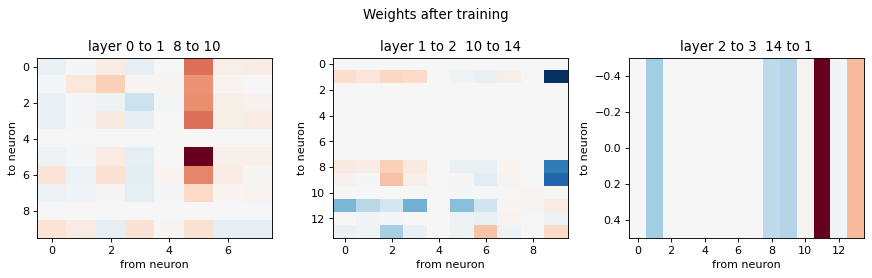

In [6]:
model = DJINN_Regressor(
    n_trees=1,
    max_tree_depth=depth,
    learning_rate=0.005,
    epochs=300,
    random_state=0,
)
model.fit(X_train, y_train)
print(f"R2 on the test set: {model.score(X_test, y_test):.3f}")

net = model.models_[0]
trained = [layer.weight.detach().numpy() for layer in net.hidden_layers]
trained.append(net.output_layer.weight.detach().numpy())
show_weights(trained, "Weights after training")

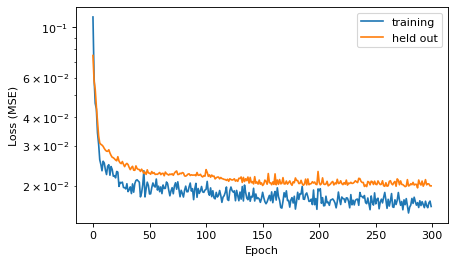

In [7]:
# With one tree, train_cost and valid_cost are single curves
fig, ax = plt.subplots(figsize=(6, 3.5), dpi=80)
ax.plot(model.nninfo_["train_cost"], label="training")
ax.plot(model.nninfo_["valid_cost"], label="held out")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (MSE)")
ax.set_yscale("log")
ax.legend()
plt.show()